# 01 · Exploratory data analysis

What the training corpora look like before any modelling: class balance, body length, dates, message structure and duplicates. Corpus choice, licences and the leakage risks measured on raw files are in [`docs/data.md`](../docs/data.md).

Every number below comes from `mailguard.data.records`, which keeps counts, flags, dates and hashes only. No message text, address or URL appears in this notebook.

## TL;DR

| Finding | Number | Consequence |
|---|---|---|
| Phishing is the majority class | 57.1% phishing, 29.5% ham, 13.5% spam (14,084 messages) | No accuracy. Headline metrics are PR-AUC and recall at a fixed false-positive rate. |
| Phishing never overlaps ham in time | Ham and spam: 2001-2002. Phishing: 2004-2007 and 2015-2025. Nothing in 2008-2014. | Any time-correlated trait is a label proxy. No date features; temporal checks run on phishing only. |
| HTML is an era marker, not a phishing marker | HTML body: 4.5% of ham vs 94.1% of phishing | No standalone "has HTML" feature. Text features use `Email.body_text` for every message. |
| Length separates little | Median readable body: 904 (phishing) to 1,066 (spam) characters | Length is at best a weak feature. |
| Some phishing has no text at all | 3.2% of phishing (0% of ham) is image- or attachment-only | A text model is blind to these. URL and attachment features, then the agent, must cover them. |
| Campaigns repeat | 21.3% of messages repeat an earlier body after normalisation: 41.5% of 2004-2007 phishing, 20.6% of 2015-2025 phishing, 18.4% of spam, 1.9% of ham | Random splits would leak. The split must keep each duplicate cluster on one side. |
| Labels are consistent | 2 of 1,254 duplicate clusters mix labels (ham/spam only) | Corpus-level labels can be trusted at campaign level. |
| The planned temporal check is clean | 6 clusters (22 messages) cross the 2019/2020 phishing cut | Grouped by cluster, "train up to 2019, test 2020-2025" measures generalisation to new campaigns. |
| Dates are mostly usable | 152 messages (1.1%) have a missing or implausible `Date`, mostly in spam | `Date` stays untrusted; time-based analysis uses the corpus file period. |


**Reproduce:** `make data` (downloads and verifies the corpora), then `make eda` (re-executes this notebook in place, about 30 s).

## Setup

In [1]:
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

from mailguard.config import get_settings
from mailguard.data.records import iter_records

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DATA_DIR = get_settings().data_dir
RAW = (DATA_DIR if DATA_DIR.is_absolute() else ROOT / DATA_DIR) / "raw"

LABELS = ["ham", "spam", "phishing"]
# Categorical slots 1-3 of the project palette, in fixed order. Validated for
# colour-vision deficiency; aqua is below 3:1 contrast, so every chart has a table.
COLORS = {"ham": "#2a78d6", "spam": "#eb6834", "phishing": "#1baf7a"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_2,
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.titlesize": 12,
        "axes.titlepad": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "font.size": 10,
        "legend.frameon": False,
        "figure.dpi": 100,
    }
)
pd.set_option("display.precision", 3)


def label_legend(ax: plt.Axes, **kwargs: object) -> None:
    handles = [Patch(color=COLORS[label], label=label) for label in LABELS]
    ax.legend(handles=handles, **kwargs)

In [2]:
def era(file: str) -> str:
    if not file.startswith("phishing"):
        return "2002"
    return "2004-2007" if file.endswith(".mbox") else "2015-2025"


records = pd.DataFrame(asdict(r) for r in iter_records(RAW))
records["era"] = records["file"].map(era)
records["group"] = np.where(
    records["label"] == "phishing", "phishing " + records["era"], records["label"]
)
records["year"] = records["date"].dt.year
records["no_text"] = records["body_chars"] == 0
print(f"{len(records):,} messages from {records['file'].nunique()} files")

14,084 messages from 20 files


## 1. Class balance

In [3]:
balance = records["label"].value_counts().reindex(LABELS).to_frame("messages")
balance["share"] = (balance["messages"] / balance["messages"].sum()).round(3)
balance

,messages,share
label,,
ham,4150,0.295
spam,1896,0.135
phishing,8038,0.571


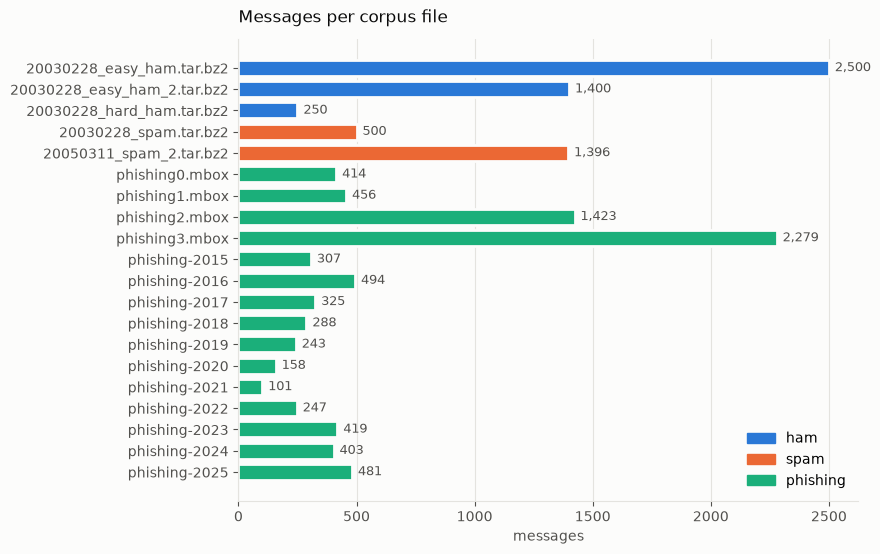

In [4]:
per_file = records.groupby(["file", "label"], sort=False).size().reset_index(name="messages")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    per_file["file"],
    per_file["messages"],
    color=per_file["label"].map(COLORS),
    height=0.75,
    edgecolor=SURFACE,
    linewidth=2,
)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, n in enumerate(per_file["messages"]):
    ax.text(n + 25, y, f"{n:,}", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("messages")
ax.set_title("Messages per corpus file")
label_legend(ax, loc="lower right")
plt.show()

Phishing is the majority class (57%). In a real inbox it is well under 1%, so accuracy and precision measured on this mix say little about production. The headline metrics will be PR-AUC and recall at a fixed false-positive rate, which do not depend on the class prior.

## 2. Body length

In [5]:
lengths = records.groupby("label")["body_chars"].describe(percentiles=[0.05, 0.5, 0.95])
lengths = lengths.reindex(LABELS)[["count", "5%", "50%", "95%", "max"]].round().astype(int)
lengths["no readable text"] = records.groupby("label")["no_text"].mean().reindex(LABELS).round(3)
lengths

,count,5%,50%,95%,max,no readable text
label,,,,,,
ham,4150,194,974,5553,194824,0.000
spam,1896,173,1066,7528,126335,0.014
phishing,8038,58,904,2711,1023581,0.032


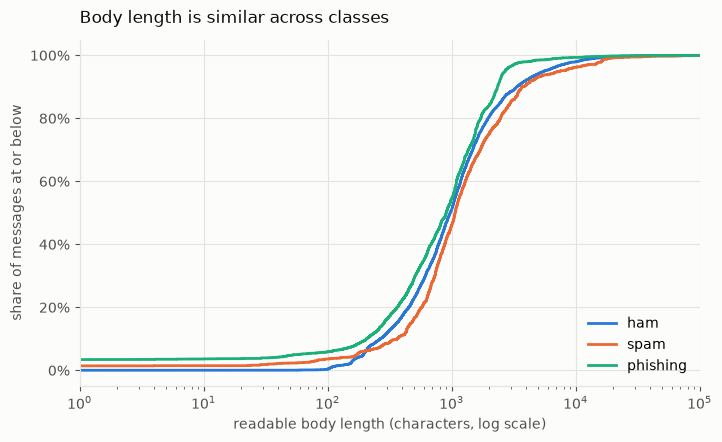

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label in LABELS:
    chars = np.sort(records.loc[records["label"] == label, "body_chars"].clip(lower=1))
    ax.step(
        chars,
        np.arange(1, len(chars) + 1) / len(chars),
        where="post",
        color=COLORS[label],
        linewidth=2,
        label=label,
    )
ax.set_xscale("log")
ax.set_xlim(1, 1e5)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("readable body length (characters, log scale)")
ax.set_ylabel("share of messages at or below")
ax.set_title("Body length is similar across classes")
ax.legend(loc="lower right")
plt.show()

Median lengths sit between 900 and 1,070 characters for all three classes, so length alone separates little. The visible difference is at the low end: a block of phishing messages has no readable text at all (the step at 1 character). Those are image-only or attachment-only messages. A text model is blind to them, which is one of the cases the URL and attachment features, and later the agent, have to cover.

## 3. Dates

In [7]:
plausible = records["year"].between(1995, 2026)
dates = records.groupby("file", sort=False).agg(
    label=("label", "first"),
    messages=("id", "size"),
    median_year=("year", "median"),
    missing_date=("date", lambda s: s.isna().sum()),
)
dates["median_year"] = dates["median_year"].astype("Int64")
implausible = records["year"].notna() & ~plausible
dates["implausible_year"] = implausible.groupby(records["file"], sort=False).sum()
dates

,label,messages,median_year,missing_date,implausible_year
file,,,,,
20030228_easy_ham.tar.bz2,ham,2500,2002,0,1
20030228_easy_ham_2.tar.bz2,ham,1400,2002,0,0
20030228_hard_ham.tar.bz2,ham,250,2002,0,0
20030228_spam.tar.bz2,spam,500,2002,2,14
20050311_spam_2.tar.bz2,spam,1396,2002,0,53
phishing0.mbox,phishing,414,2005,0,1
phishing1.mbox,phishing,456,2005,0,1
phishing2.mbox,phishing,1423,2006,1,11
phishing3.mbox,phishing,2279,2007,1,0


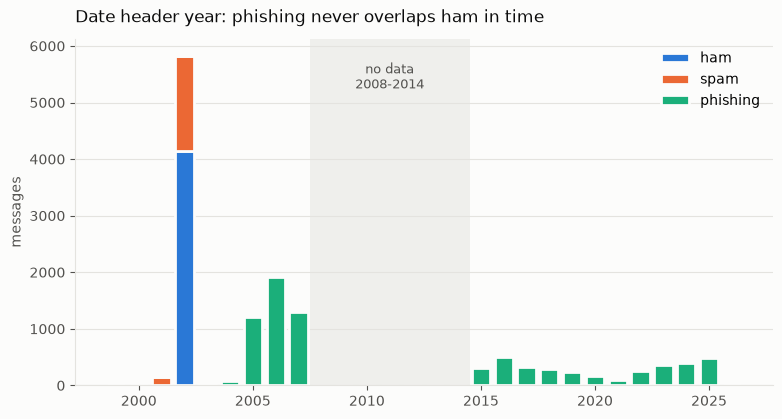

Dropped from the chart: 152 messages with a missing or implausible date


In [8]:
by_year = (
    records[plausible]
    .groupby(["year", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(1999, 2027), columns=LABELS, fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(len(by_year))
for label in LABELS:
    ax.bar(
        by_year.index,
        by_year[label],
        bottom=bottom,
        color=COLORS[label],
        width=0.8,
        edgecolor=SURFACE,
        linewidth=2,
        label=label,
    )
    bottom += by_year[label].to_numpy()
ax.axvspan(2007.5, 2014.5, color=GRID, alpha=0.5, linewidth=0)
ax.text(2011, bottom.max() * 0.9, "no data\n2008-2014", ha="center", color=INK_2, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylabel("messages")
ax.set_title("Date header year: phishing never overlaps ham in time")
ax.legend(loc="upper right")
plt.show()

print(f"Dropped from the chart: {(~plausible).sum()} messages with a missing or implausible date")

Each file is internally consistent: its median Date-header year matches the period it was collected in. Across files, ham and spam are 2001-2002, phishing is 2004-2007 and 2015-2025, with nothing in between. Any feature that correlates with time (HTML usage, authentication headers, mail client fingerprints) is therefore also a label proxy. Broken dates are concentrated in spam (`20050311_spam_2`), plus 55 undated messages in `phishing-2023`.

## 4. Message structure

In [9]:
structure = (
    pd.DataFrame(
        {
            "plain-text body": records["has_text"],
            "HTML body": records["has_html"],
            "at least one URL": records["n_urls"] > 0,
            "attachment": records["n_attachments"] > 0,
            "parser defect": records["n_defects"] > 0,
        }
    )
    .groupby(records["label"])
    .mean()
    .reindex(LABELS)
    .T.round(3)
)
structure

label,ham,spam,phishing
plain-text body,0.971,0.550,0.283
HTML body,0.045,0.539,0.941
at least one URL,0.873,0.831,0.939
attachment,0.031,0.013,0.134
parser defect,0.000,0.034,0.005


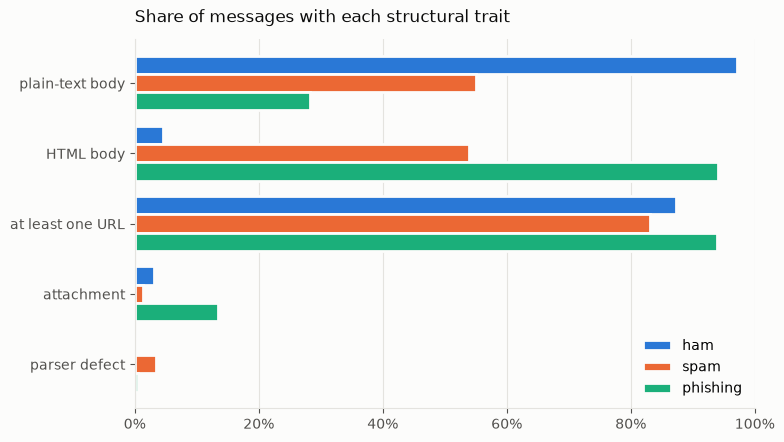

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
rows = np.arange(len(structure))
height = 0.26
for i, label in enumerate(LABELS):
    ax.barh(
        rows + (i - 1) * height,
        structure[label],
        height=height,
        color=COLORS[label],
        edgecolor=SURFACE,
        linewidth=2,
        label=label,
    )
ax.set_yticks(rows, structure.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 1)
ax.set_title("Share of messages with each structural trait")
ax.legend(loc="lower right")
plt.show()

The 2002 ham is almost all plain text (mailing lists of the time) while phishing is almost all HTML. This is the era gap again, not a property of phishing: a modern legitimate newsletter is HTML too. Week 3 consequences:

- no standalone "has HTML" feature;
- text features computed on `Email.body_text`, the same visible text whether it came from plain text or HTML;
- the URL and attachment rates are closer across classes and carry more transferable signal.

## 5. Duplicates

Two fingerprints per message, both on the readable body (`mailguard.data.dedup`):

- **exact**: identical text;
- **normalised**: identical after case and Unicode folding, with URLs and numbers masked. Campaigns personalise links and amounts per recipient, so this catches copies of the same campaign.

A message counts as a duplicate when an earlier message has the same fingerprint. Messages without readable text have no fingerprint.

In [11]:
GROUPS = ["ham", "spam", "phishing 2004-2007", "phishing 2015-2025"]
with_text = records[~records["no_text"]]


def duplicate_rate(fp: str) -> pd.Series:
    # pandas treats missing values as equal to each other: drop them first.
    rows = with_text[with_text[fp].notna()]
    is_dup = rows.duplicated(fp, keep="first")
    return is_dup.groupby(rows["group"]).mean().reindex(GROUPS).round(3)


dups = pd.DataFrame(
    {"exact": duplicate_rate("exact_fp"), "normalised": duplicate_rate("normalised_fp")}
)
overall = with_text["normalised_fp"].dropna().duplicated().mean()
print(f"Overall: {overall:.1%} of messages repeat an earlier body after normalisation")
dups

Overall: 21.3% of messages repeat an earlier body after normalisation


,exact,normalised
group,,
ham,0.012,0.019
spam,0.127,0.184
phishing 2004-2007,0.357,0.415
phishing 2015-2025,0.144,0.206


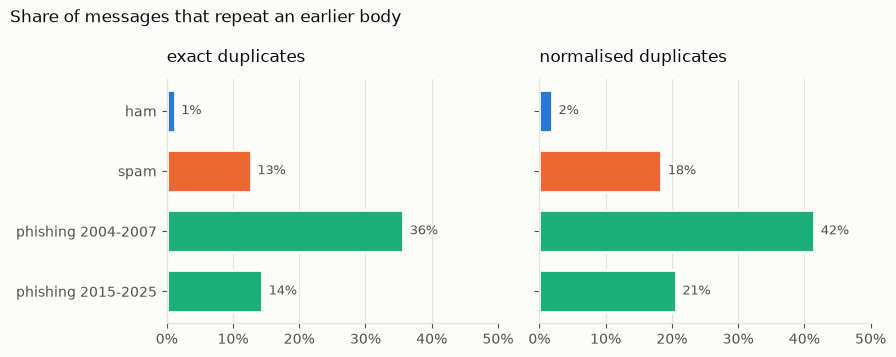

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True, sharex=True)
group_colors = [COLORS[g.split()[0]] for g in GROUPS]
for ax, column in zip(axes, dups.columns, strict=True):
    ax.barh(GROUPS, dups[column], color=group_colors, height=0.7, edgecolor=SURFACE, linewidth=2)
    for y, rate in enumerate(dups[column]):
        ax.text(rate + 0.01, y, f"{rate:.0%}", va="center", color=INK_2, fontsize=9)
    ax.set_title(f"{column} duplicates")
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 0.5)
axes[0].invert_yaxis()
fig.suptitle("Share of messages that repeat an earlier body", x=0.01, ha="left", color=INK)
fig.tight_layout()
plt.show()

Do duplicates cross the boundaries that matter for evaluation?

In [13]:
clusters = with_text.groupby("normalised_fp").agg(
    messages=("id", "size"),
    labels=("label", "nunique"),
    eras=("era", "nunique"),
    files=("file", "nunique"),
    phishing_years=("file", lambda f: frozenset(f)),
)
repeated = clusters[clusters["messages"] > 1]

# Planned temporal check (docs/data.md): train on phishing up to 2019, test on 2020-2025.
TRAIN_FILES = {f"phishing-{y}" for y in range(2015, 2020)}
TEST_FILES = {f"phishing-{y}" for y in range(2020, 2026)}
spans_cut = repeated["phishing_years"].map(lambda f: bool(f & TRAIN_FILES) and bool(f & TEST_FILES))

summary = pd.Series(
    {
        "clusters with 2+ messages": len(repeated),
        "largest cluster": repeated["messages"].max(),
        "clusters spanning 2+ files": (repeated["files"] > 1).sum(),
        "clusters with conflicting labels": (repeated["labels"] > 1).sum(),
        "clusters spanning both phishing eras": (repeated["eras"] > 1).sum(),
        "clusters spanning the 2019/2020 cut": spans_cut.sum(),
        "messages in those clusters": repeated.loc[spans_cut, "messages"].sum(),
    }
)
summary.to_frame("value")

,value
clusters with 2+ messages,1254
largest cluster,71
clusters spanning 2+ files,197
clusters with conflicting labels,2
clusters spanning both phishing eras,1
clusters spanning the 2019/2020 cut,6
messages in those clusters,22


Duplication is a campaign effect: phishing repeats far more than ham, and older phishing repeats most. Two consequences for week 4:

1. **Random splits would leak.** Copies of the same campaign would land in train and test, and the model would be graded on messages it has effectively seen. The split must group messages by normalised fingerprint so that a cluster stays on one side.
2. **The temporal check needs the same grouping.** Some campaigns cross the 2019/2020 cut. Those clusters are assigned to the train side, so test campaigns are new.

Label conflicts are negligible (a handful of ham/spam clusters, no phishing), so the corpus labels are consistent at the campaign level.